# LM13 Lab — Probability Foundations and Bayes

Companion notebook to **From Calculus to Kelly, LM13**. It rebuilds the module's exhibits and computational examples from the TR23 closes, recounts every threshold with exact fractions, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's returns, the pair space and an exact recount of the threshold days |
| 2 | Events and the axioms: indicators, (13.1), (13.2), Example 2 and the counts of Exhibit 2 |
| 3 | Conditional probability: the case (Exhibit 1), Exhibit 3, Example 3, Example 4 |
| 4 | Independence: Exhibit 4, Example 5 by enumeration, Example 6 and other block lengths |
| 5 | Total probability and Bayes' rule: Exhibit 5, Example 7, Example 8 three ways, Example 9 |
| 6 | Random variables: Example 10 by enumeration, Exhibit 6, Exhibit 7, the step at a point |
| 7 | Practice problems 4, 5, 6, 7, 10 and 11, and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv` (`date`, `price`): the closes of the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`, data_id TAIEX) from 2 January 2003 to 8 October 2026. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** TR23: $T=5{,}849$ simple daily returns from 3 January 2003; the pair space is the 5,848 return dates with a previous return, triples the 5,847 dates with two. Thresholds are inclusive and counted with one guard, `R <= x + 1e-12` and `R >= x - 1e-12`, checked against exact fractions. A fall is $R\le-3\%$ and a big move $\lvert R\rvert\ge2\%$. The limit regimes are the return dates up to 29 May 2015 (7%) and from 1 June 2015 (10%). Every frequency describes the sample; the independent-days figures are a model, and the regime comparison is a stability check. Each `show` line prints a value beside the module's printed value and stops if they differ.

In [1]:
from fractions import Fraction
from itertools import product
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
EPS = 1e-12
pl.Config.set_tbl_rows(20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value; stop if they differ at the printed precision
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)

## Part 1 — Data: returns, the pair space and exact ties

The return of a day is the close divided by the previous close, minus 1. `shift(1)` leaves a null in the first row, so `R` has one null and `R_prev`, yesterday's return, has two.

In [2]:
tr = pl.read_csv(DATA / "taiex_tr.csv").sort("date")
df = (tr.with_columns(R=pl.col("price") / pl.col("price").shift(1) - 1)
        .with_columns(R_prev=pl.col("R").shift(1), R_prev2=pl.col("R").shift(2), prev_date=pl.col("date").shift(1)))
days = df.drop_nulls("R")                  # the T returns
pairs = df.drop_nulls("R_prev")            # the pair space
triples = df.drop_nulls("R_prev2")         # three consecutive returns
T = days.height
show("closes", tr.height, ",", "5,850")
show("T", T, ",", "5,849")
show("pair space", pairs.height, ",", "5,848")
show("triples", triples.height, ",", "5,847")
print("returns", days["date"][0], "to", days["date"][-1], "; pairs from", pairs["date"][0], "; triples from", triples["date"][0])
show("first return", days["R"][0], "+.2%", "+2.24%")

closes: 5,850   [book: 5,850]
T: 5,849   [book: 5,849]
pair space: 5,848   [book: 5,848]
triples: 5,847   [book: 5,847]
returns 2003-01-03 to 2026-10-08 ; pairs from 2003-01-06 ; triples from 2003-01-07
first return: +2.24%   [book: +2.24%]


In [3]:
# exact returns from the two-decimal closes: the guard must agree with them at every threshold
closes = [Fraction(f"{x:.2f}") for x in tr["price"]]
assert all(float(c) == x for c, x in zip(closes, tr["price"]))
RF = [b / a - 1 for a, b in zip(closes, closes[1:])]
R = days["R"].to_numpy()
ties = {c: sum(r == Fraction(c, 100) for r in RF) for c in range(-5, 6)}
print("returns exactly equal to c% for c = -5..5:", ties)
print("distinct returns:", len(set(RF)))
for c in range(-10, 11):
    assert ((R <= c / 100 + EPS) == np.array([r <= Fraction(c, 100) for r in RF])).all(), c
    assert ((R >= c / 100 - EPS) == np.array([r >= Fraction(c, 100) for r in RF])).all(), c
print("the guarded counts agree with the exact counts at every whole percent from -10% to +10%")

returns exactly equal to c% for c = -5..5: {-5: 0, -4: 0, -3: 0, -2: 0, -1: 0, 0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0}
distinct returns: 5849
the guarded counts agree with the exact counts at every whole percent from -10% to +10%


## Part 2 — Events and the axioms

An event on the pair space is a boolean column. Inclusion–exclusion (13.1) and the union bound (13.2) on Example 2: $A$ holds the days down 2% or more, $B$ the days after one.

In [4]:
cnt = pairs.select(
    A=(pl.col("R") <= -0.02 + EPS).sum(),
    B=(pl.col("R_prev") <= -0.02 + EPS).sum(),
    AB=((pl.col("R") <= -0.02 + EPS) & (pl.col("R_prev") <= -0.02 + EPS)).sum(),
    AorB=((pl.col("R") <= -0.02 + EPS) | (pl.col("R_prev") <= -0.02 + EPS)).sum(),
).row(0, named=True)
nP = pairs.height
print(cnt)
assert cnt["AorB"] == cnt["A"] + cnt["B"] - cnt["AB"]            # (13.1) in counts
print("regions of the venn diagram: A only", cnt["A"] - cnt["AB"], "both", cnt["AB"],
      "B only", cnt["B"] - cnt["AB"], "neither", nP - cnt["AorB"])
show("E2 union", cnt["AorB"] / nP, ".2%", "7.97%")
show("E2 union bound", (cnt["A"] + cnt["B"]) / nP, ".2%", "8.62%")
show("E2 Pr(A)", cnt["A"] / nP, ".4f", "0.0431")
show("E2 both if independent (from the printed 0.0431)", nP * 0.0431 ** 2, ".1f", "10.9")

{'A': 252, 'B': 252, 'AB': 38, 'AorB': 466}
regions of the venn diagram: A only 214 both 38 B only 214 neither 5382
E2 union: 7.97%   [book: 7.97%]
E2 union bound: 8.62%   [book: 8.62%]
E2 Pr(A): 0.0431   [book: 0.0431]
E2 both if independent (from the printed 0.0431): 10.9   [book: 10.9]


## Part 3 — Conditional probability

The case (Exhibit 1): $A$ is a fall of 3% or more today, $B$ a move of 2% or more either way yesterday.

In [5]:
fall = pl.col("R") <= -0.03 + EPS
big = (pl.col("R_prev") <= -0.02 + EPS) | (pl.col("R_prev") >= 0.02 - EPS)
case = (pairs.with_columns(fall=fall, big=big)
             .group_by("big", "fall").agg(days=pl.len())
             .sort("big", "fall", descending=True))
print(case)
c = pairs.select(AB=(fall & big).sum(), A=fall.sum(), B=big.sum()).row(0, named=True)
show("falls after a big move", c["AB"], "d", "32")
show("falls", c["A"], "d", "108")
show("days after a big move", c["B"], "d", "489")
show("Pr(A | B)", c["AB"] / c["B"], ".2%", "6.54%")
show("Pr(A | not B)", (c["A"] - c["AB"]) / (nP - c["B"]), ".2%", "1.42%")
show("hit rate Pr(B | A)", c["AB"] / c["A"], ".2%", "29.63%")
show("false-alarm rate Pr(B | not A)", (c["B"] - c["AB"]) / (nP - c["A"]), ".2%", "7.96%")
show("Pr(B)", c["B"] / nP, ".2%", "8.36%")
show("falls among all days", c["A"] / T, ".2%", "1.85%")

shape: (4, 3)
┌───────┬───────┬──────┐
│ big   ┆ fall  ┆ days │
│ ---   ┆ ---   ┆ ---  │
│ bool  ┆ bool  ┆ u32  │
╞═══════╪═══════╪══════╡
│ true  ┆ true  ┆ 32   │
│ true  ┆ false ┆ 457  │
│ false ┆ true  ┆ 76   │
│ false ┆ false ┆ 5283 │
└───────┴───────┴──────┘
falls after a big move: 32   [book: 32]
falls: 108   [book: 108]
days after a big move: 489   [book: 489]
Pr(A | B): 6.54%   [book: 6.54%]
Pr(A | not B): 1.42%   [book: 1.42%]
hit rate Pr(B | A): 29.63%   [book: 29.63%]
false-alarm rate Pr(B | not A): 7.96%   [book: 7.96%]
Pr(B): 8.36%   [book: 8.36%]
falls among all days: 1.85%   [book: 1.85%]


Exhibit 3: the share of days that fell 3% or more, by yesterday's return. A bucket $(lo, hi]$ is "not at or below $lo$, and at or below $hi$", with the guard at both ends.

shape: (8, 4)
┌────────────┬──────┬───────┬──────────┐
│ bucket     ┆ days ┆ falls ┆ share    │
│ ---        ┆ ---  ┆ ---   ┆ ---      │
│ str        ┆ i64  ┆ i64   ┆ f64      │
╞════════════╪══════╪═══════╪══════════╡
│ (None, -3] ┆ 108  ┆ 13    ┆ 0.12037  │
│ (-3, -2]   ┆ 144  ┆ 8     ┆ 0.055556 │
│ (-2, -1]   ┆ 516  ┆ 15    ┆ 0.02907  │
│ (-1, 0]    ┆ 1875 ┆ 30    ┆ 0.016    │
│ (0, 1]     ┆ 2272 ┆ 23    ┆ 0.010123 │
│ (1, 2]     ┆ 696  ┆ 8     ┆ 0.011494 │
│ (2, 3]     ┆ 170  ┆ 8     ┆ 0.047059 │
│ (3, None]  ┆ 67   ┆ 3     ┆ 0.044776 │
└────────────┴──────┴───────┴──────────┘
after a fall of 3% or more: 12.04%   [book: 12.04%]
after a rise of more than 3%: 4.48%   [book: 4.48%]


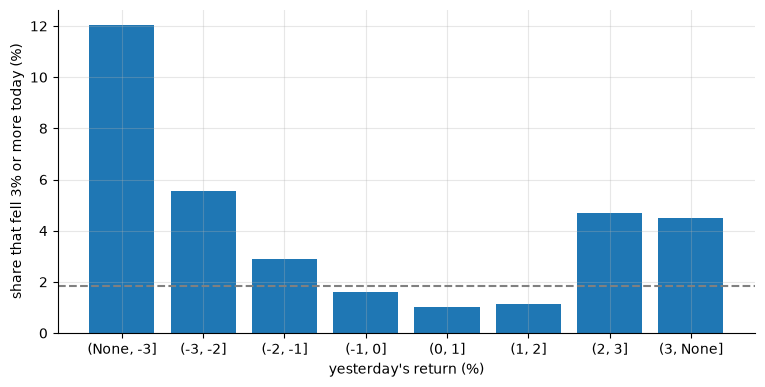

In [6]:
edges = [(None, -3), (-3, -2), (-2, -1), (-1, 0), (0, 1), (1, 2), (2, 3), (3, None)]
rows = []
for lo, hi in edges:
    m = pl.lit(True)
    if lo is not None:
        m = m & ~(pl.col("R_prev") <= lo / 100 + EPS)
    if hi is not None:
        m = m & (pl.col("R_prev") <= hi / 100 + EPS)
    d = pairs.select(days=m.sum(), falls=(m & fall).sum()).row(0, named=True)
    rows.append({"bucket": f"({lo}, {hi}]", **d, "share": d["falls"] / d["days"]})
buckets = pl.DataFrame(rows)
print(buckets)
assert buckets["days"].sum() == nP and buckets["falls"].sum() == c["A"]
show("after a fall of 3% or more", rows[0]["share"], ".2%", "12.04%")
show("after a rise of more than 3%", rows[-1]["share"], ".2%", "4.48%")
plt.bar(buckets["bucket"], buckets["share"] * 100)
plt.axhline(100 * c["A"] / nP, ls="--", c="grey")
plt.ylabel("share that fell 3% or more today (%)"); plt.xlabel("yesterday's return (%)")
plt.show()

In [7]:
# two falls in a row, and inside the tail
ff = pairs.select(both=(fall & (pl.col("R_prev") <= -0.03 + EPS)).sum(),
                  yest=(pl.col("R_prev") <= -0.03 + EPS).sum()).row(0, named=True)
show("Example 3 Pr(fall today | fall yesterday)", ff["both"] / ff["yest"], ".2%", "12.04%")
show("Example 3 both", ff["both"] / nP, ".3%", "0.222%")
show("Example 3 ratio to the base rate", (ff["both"] / ff["yest"]) / (c["A"] / nP), ".1f", "6.5")
show("Example 3 pairs if independent", ff["yest"] * c["A"] / nP, ".1f", "2.0")
t = days.select(n3=(pl.col("R") <= -0.03 + EPS).sum(), n4=(pl.col("R") <= -0.04 + EPS).sum(),
                n5=(pl.col("R") <= -0.05 + EPS).sum(),
                mean3=pl.col("R").filter(pl.col("R") <= -0.03 + EPS).mean()).row(0, named=True)
show("Example 4 Pr(R <= -5% | R <= -3%)", t["n5"] / t["n3"], ".1%", "13.9%")
show("Example 4 Pr(R <= -4% | R <= -3%)", t["n4"] / t["n3"], ".1%", "40.7%")
show("Example 4 average of the falls", t["mean3"], ".2%", "-4.06%")

Example 3 Pr(fall today | fall yesterday): 12.04%   [book: 12.04%]
Example 3 both: 0.222%   [book: 0.222%]
Example 3 ratio to the base rate: 6.5   [book: 6.5]
Example 3 pairs if independent: 2.0   [book: 2.0]
Example 4 Pr(R <= -5% | R <= -3%): 13.9%   [book: 13.9%]
Example 4 Pr(R <= -4% | R <= -3%): 40.7%   [book: 40.7%]
Example 4 average of the falls: -4.06%   [book: -4.06%]


## Part 4 — Independence

Exhibit 4: signs of consecutive days, and the counts that independence with the same margins would give.

In [8]:
signs = (pairs.with_columns(yd=pl.col("R_prev") < 0, td=pl.col("R") < 0)
              .group_by("yd", "td").agg(n=pl.len()).sort("yd", "td", descending=True))
print(signs)
s = {(r["yd"], r["td"]): r["n"] for r in signs.iter_rows(named=True)}
row = {y: s[(y, True)] + s[(y, False)] for y in (True, False)}
col = {d: s[(True, d)] + s[(False, d)] for d in (True, False)}
show("down after down", s[(True, True)], ",", "1,226")
show("share down after down", s[(True, True)] / row[True], ".4f", "0.4639")
show("share down after up", s[(False, True)] / row[False], ".4f", "0.4424")
for y in (True, False):
    for d in (True, False):
        print("if independent", "down" if y else "up", "->", "down" if d else "up", f"{row[y] * col[d] / nP:,.1f}")
show("if independent, down after down", row[True] * col[True] / nP, ",.1f", "1,195.0")

shape: (4, 3)
┌───────┬───────┬──────┐
│ yd    ┆ td    ┆ n    │
│ ---   ┆ ---   ┆ ---  │
│ bool  ┆ bool  ┆ u32  │
╞═══════╪═══════╪══════╡
│ true  ┆ true  ┆ 1226 │
│ true  ┆ false ┆ 1417 │
│ false ┆ true  ┆ 1418 │
│ false ┆ false ┆ 1787 │
└───────┴───────┴──────┘
down after down: 1,226   [book: 1,226]
share down after down: 0.4639   [book: 0.4639]
share down after up: 0.4424   [book: 0.4424]
if independent down -> down 1,195.0
if independent down -> up 1,448.0
if independent up -> down 1,449.0
if independent up -> up 1,756.0
if independent, down after down: 1,195.0   [book: 1,195.0]


In [9]:
# Example 5 by enumeration: two fair trades, four equally likely outcomes
omega = ["".join(w) for w in product("+-", repeat=2)]
pr = lambda ev: Fraction(sum(1 for w in omega if ev(w)), len(omega))
A1, A2, A3 = (lambda w: w[0] == "+"), (lambda w: w[1] == "+"), (lambda w: w[0] == w[1])
for a, b, name in ((A1, A2, "A1 A2"), (A1, A3, "A1 A3"), (A2, A3, "A2 A3")):
    print(name, pr(lambda w: a(w) and b(w)), "=", pr(a) * pr(b))
print("all three:", pr(lambda w: A1(w) and A2(w) and A3(w)), "against", pr(A1) * pr(A2) * pr(A3))

A1 A2 1/4 = 1/4
A1 A3 1/4 = 1/4
A2 A3 1/4 = 1/4
all three: 1/4 against 1/8


In [10]:
# Example 6: at least one fall of 3% or more in blocks of n sessions, model against data
p1 = c["A"] / T
fall_np = R <= -0.03 + EPS


def blocks(n):
    nb = T // n
    return nb, T - nb * n, int(fall_np[: nb * n].reshape(nb, n).any(axis=1).sum())


show("Pr(A), five digits", p1, ".4%", "1.8465%")
show("model, 20 sessions", 1 - (1 - 0.018465) ** 20, ".1%", "31.1%")
nb, left, hit = blocks(20)
print("blocks of 20:", nb, "returns excluded:", left, "with a fall:", hit)
show("model blocks", nb * 0.311, ".0f", "91")
show("data, 20 sessions", hit / nb, ".1%", "20.9%")
for n in (5, 10, 60):       # not in the module: the same comparison for other block lengths
    nb, left, hit = blocks(n)
    print(f"{n:>2} sessions: model {1 - (1 - p1) ** n:.1%}, data {hit}/{nb} = {hit / nb:.1%} ({left} returns excluded)")

Pr(A), five digits: 1.8465%   [book: 1.8465%]
model, 20 sessions: 31.1%   [book: 31.1%]
blocks of 20: 292 returns excluded: 9 with a fall: 61
model blocks: 91   [book: 91]
data, 20 sessions: 20.9%   [book: 20.9%]
 5 sessions: model 8.9%, data 88/1169 = 7.5% (4 returns excluded)
10 sessions: model 17.0%, data 73/584 = 12.5% (9 returns excluded)
60 sessions: model 67.3%, data 42/97 = 43.3% (29 returns excluded)


## Part 5 — Total probability and Bayes' rule

Exhibit 5 and Example 7: the 7% and 10% limit regimes (a stability check). Pairs count only when both days lie in one regime.

In [11]:
reg = pl.when(pl.col("date") <= pl.lit("2015-05-29")).then(pl.lit("7%")).otherwise(pl.lit("10%"))
by_day = (days.with_columns(regime=reg)
              .group_by("regime").agg(days=pl.len(), falls=(pl.col("R") <= -0.03 + EPS).sum())
              .sort("regime", descending=True))
print(by_day)
prev_reg = pl.when(pl.col("prev_date") <= pl.lit("2015-05-29")).then(pl.lit("7%")).otherwise(pl.lit("10%"))
inside = (pairs.with_columns(regime=reg, prev_regime=prev_reg)
               .filter(pl.col("regime") == pl.col("prev_regime"))
               .group_by("regime").agg(pairs=pl.len(), falls=fall.sum(), big=big.sum(), both=(fall & big).sum())
               .sort("regime", descending=True))
print(inside)
d7, d10 = (by_day.filter(pl.col("regime") == pl.lit(r)).row(0, named=True) for r in ("7%", "10%"))
show("share of days, 7%", d7["days"] / T, ".2%", "52.61%")
show("fall share, 7%", d7["falls"] / d7["days"], ".2%", "2.34%")
show("fall share, 10%", d10["falls"] / d10["days"], ".2%", "1.30%")
total = Fraction(d7["falls"], d7["days"]) * Fraction(d7["days"], T) + Fraction(d10["falls"], d10["days"]) * Fraction(d10["days"], T)
print("(13.8) in counts:", total, "=", Fraction(c["A"], T))
show("Example 7 Pr(10% regime | fall)", d10["falls"] / (d7["falls"] + d10["falls"]), ".1%", "33.3%")
show("Example 7 from the rounded 2.34%, 1.30%, 52.6%, 47.4%", 0.0130 * 0.474 / (0.0234 * 0.526 + 0.0130 * 0.474), ".1%", "33.4%")
i10 = inside.filter(pl.col("regime") == pl.lit("10%")).row(0, named=True)
show("10% regime: share that fell after a big move", i10["both"] / i10["big"], ".2%", "8.06%")
show("10% regime: hit rate", i10["both"] / i10["falls"], ".2%", "41.67%")

shape: (2, 3)
┌────────┬──────┬───────┐
│ regime ┆ days ┆ falls │
│ ---    ┆ ---  ┆ ---   │
│ str    ┆ u32  ┆ u32   │
╞════════╪══════╪═══════╡
│ 7%     ┆ 3077 ┆ 72    │
│ 10%    ┆ 2772 ┆ 36    │
└────────┴──────┴───────┘
shape: (2, 5)
┌────────┬───────┬───────┬─────┬──────┐
│ regime ┆ pairs ┆ falls ┆ big ┆ both │
│ ---    ┆ ---   ┆ ---   ┆ --- ┆ ---  │
│ str    ┆ u32   ┆ u32   ┆ u32 ┆ u32  │
╞════════╪═══════╪═══════╪═════╪══════╡
│ 7%     ┆ 3076  ┆ 72    ┆ 303 ┆ 17   │
│ 10%    ┆ 2771  ┆ 36    ┆ 186 ┆ 15   │
└────────┴───────┴───────┴─────┴──────┘
share of days, 7%: 52.61%   [book: 52.61%]
fall share, 7%: 2.34%   [book: 2.34%]
fall share, 10%: 1.30%   [book: 1.30%]
(13.8) in counts: 108/5849 = 108/5849
Example 7 Pr(10% regime | fall): 33.3%   [book: 33.3%]
Example 7 from the rounded 2.34%, 1.30%, 52.6%, 47.4%: 33.4%   [book: 33.4%]
10% regime: share that fell after a big move: 8.06%   [book: 8.06%]
10% regime: hit rate: 41.67%   [book: 41.67%]


In [12]:
# Example 8 three ways
base, hit, alarm = c["A"] / nP, c["AB"] / c["A"], (c["B"] - c["AB"]) / (nP - c["A"])
show("(a) counts", c["AB"] / c["B"], ".2%", "6.54%")
show("(b) (13.9), four digits", 0.01847 * 0.2963 / (0.01847 * 0.2963 + 0.98153 * 0.07962), ".2%", "6.54%")
show("(b) the case's rounded inputs", 0.0185 * 0.296 / (0.0185 * 0.296 + 0.9815 * 0.0796), ".2%", "6.55%")
show("(c) prior odds", c["A"] / (nP - c["A"]), ".6f", "0.018815")
show("(c) likelihood ratio", hit / alarm, ".4f", "3.7215")
show("(c) posterior odds", 0.018815 * 3.7215, ".5f", "0.07002")
show("(c) probability", 0.07002 / 1.07002, ".2%", "6.54%")
# Example 9
lr = 0.55 ** 8 * 0.45 ** 4 / 0.5 ** 12
show("manager: likelihood ratio", lr, ".4f", "1.4064")
odds = (0.1 / 0.9) * 1.4064
show("manager: posterior odds", odds, ".5f", "0.15627")
show("manager: posterior", odds / (1 + odds), ".1%", "13.5%")

(a) counts: 6.54%   [book: 6.54%]
(b) (13.9), four digits: 6.54%   [book: 6.54%]
(b) the case's rounded inputs: 6.55%   [book: 6.55%]
(c) prior odds: 0.018815   [book: 0.018815]
(c) likelihood ratio: 3.7215   [book: 3.7215]
(c) posterior odds: 0.07002   [book: 0.07002]
(c) probability: 6.54%   [book: 6.54%]
manager: likelihood ratio: 1.4064   [book: 1.4064]
manager: posterior odds: 0.15627   [book: 0.15627]
manager: posterior: 13.5%   [book: 13.5%]


## Part 6 — Random variables

Example 10 by enumeration: $X=W_2/W_0$ on two trades of LM4's bet at 25 times equity, outcomes equally likely.

In [13]:
mult = {"+": 1 + 25 * 0.02, "-": 1 - 25 * 0.01}
X = {w: mult[w[0]] * mult[w[1]] for w in omega}
pmf = {}
for w, v in X.items():
    pmf[v] = pmf.get(v, Fraction(0)) + Fraction(1, 4)
print("X:", X)
print("pmf:", pmf)
print("F_X(1.125) =", sum(p for v, p in pmf.items() if v <= 1.125), "; Pr(X < 1.125) =", sum(p for v, p in pmf.items() if v < 1.125))
g_star = 0.5 * math.log(1.5) + 0.5 * math.log(0.75)
show("half log 1.125 = g*", 0.5 * math.log(1.125), ".3%", "5.889%")
print("probability-weighted average of the half-logs minus g*:", sum(p * 0.5 * math.log(v) for v, p in pmf.items()) - g_star)

X: {'++': 2.25, '+-': 1.125, '-+': 1.125, '--': 0.5625}
pmf: {2.25: Fraction(1, 4), 1.125: Fraction(1, 2), 0.5625: Fraction(1, 4)}
F_X(1.125) = 3/4 ; Pr(X < 1.125) = 1/4
half log 1.125 = g*: 5.889%   [book: 5.889%]
probability-weighted average of the half-logs minus g*: -6.938893903907228e-18


Fhat(-3%) = 108/5849 = 0.0185
Fhat(+0%) = 2644/5849 = 0.4520
Fhat(+3%) = 5782/5849 = 0.9885
Fhat(-3%): 0.0185   [book: 0.0185]
Fhat(0): 0.4520   [book: 0.4520]
Fhat(+3%): 0.9885   [book: 0.9885]
Pr(-1% < R <= 1%): 0.7092   [book: 0.7092]
smallest 2025-04-07 -9.70% ; largest 2025-04-10 +9.25%
at r = -0.03160754139131283 : Fhat(r) = 101 / T, Pr(R < r) = 100 / T


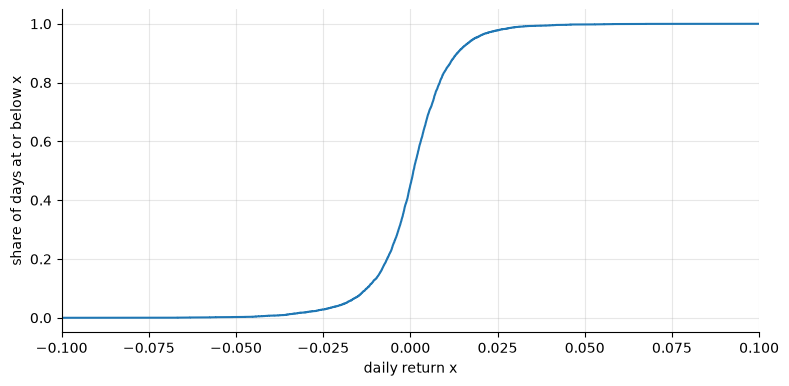

In [14]:
# Exhibit 6: the empirical distribution function (13.12), and the step at a point
x = np.sort(R)
F = np.arange(1, T + 1) / T
for c_ in (-3, 0, 3):
    n = int((R <= c_ / 100 + EPS).sum())
    print(f"Fhat({c_:+d}%) = {n}/{T} = {n / T:.4f}")
show("Fhat(-3%)", (R <= -0.03 + EPS).mean(), ".4f", "0.0185")
show("Fhat(0)", (R <= 0 + EPS).mean(), ".4f", "0.4520")
show("Fhat(+3%)", (R <= 0.03 + EPS).mean(), ".4f", "0.9885")
show("Pr(-1% < R <= 1%)", ((R <= 0.01 + EPS) & ~(R <= -0.01 + EPS)).mean(), ".4f", "0.7092")
i_min, i_max = int(R.argmin()), int(R.argmax())
print("smallest", days["date"][i_min], f"{R[i_min]:.2%}", "; largest", days["date"][i_max], f"{R[i_max]:+.2%}")
# at a return r, Fhat jumps by 1/T: Fhat(r) counts r, the share strictly below does not
r0 = x[100]
print("at r =", r0, ": Fhat(r) =", (R <= r0).sum(), "/ T, Pr(R < r) =", (R < r0).sum(), "/ T")
plt.step(np.concatenate([[-0.10], x, [0.10]]), np.concatenate([[0], F, [1]]), where="post")
plt.xlim(-0.10, 0.10); plt.xlabel("daily return x"); plt.ylabel("share of days at or below x")
plt.show()

counts: [15, 29, 64, 144, 516, 1876, 2272, 696, 170, 37, 17, 13] sum 5849
shares (%): [0.26, 0.5, 1.09, 2.46, 8.82, 32.07, 38.84, 11.9, 2.91, 0.63, 0.29, 0.22] sum of the rounded shares 99.99


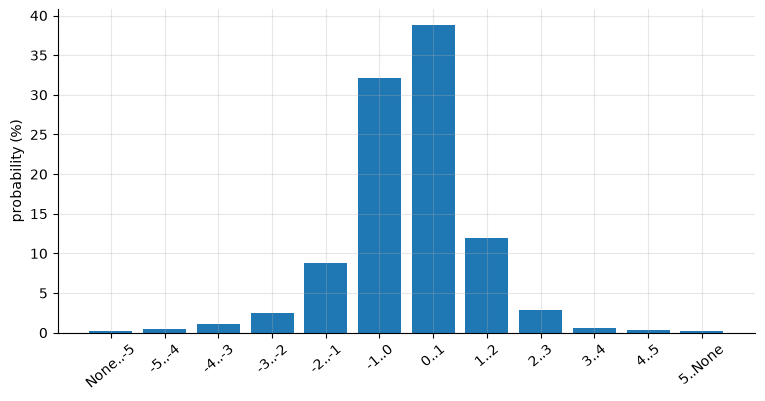

In [15]:
# Exhibit 7: the pmf of the 1% bin of R
bins = [(None, -5)] + [(k, k + 1) for k in range(-5, 5)] + [(5, None)]
counts = []
for lo, hi in bins:
    m = np.ones(T, dtype=bool)
    if lo is not None:
        m &= ~(R <= lo / 100 + EPS)
    if hi is not None:
        m &= R <= hi / 100 + EPS
    counts.append(int(m.sum()))
print("counts:", counts, "sum", sum(counts))
print("shares (%):", [round(100 * n / T, 2) for n in counts], "sum of the rounded shares", round(sum(round(100 * n / T, 2) for n in counts), 2))
assert sum(counts[:3]) == c["A"]
plt.bar([f"{lo}..{hi}" for lo, hi in bins], np.array(counts) / T * 100)
plt.xticks(rotation=40); plt.ylabel("probability (%)")
plt.show()

## Part 7 — Practice problems

Problems 4, 5, 6, 7, 10 and 11 of the module.

In [16]:
# Problem 4: A_i holds the triples whose day i fell 2% or more (5,847 triples)
f2 = R <= -0.02 + EPS
e0, e1, e2 = f2[:-2], f2[1:-1], f2[2:]
n3 = len(e0)
print("singles", int(e0.sum()), int(e1.sum()), int(e2.sum()), "| pairs", int((e0 & e1).sum()), int((e0 & e2).sum()),
      int((e1 & e2).sum()), "| all three", int((e0 & e1 & e2).sum()))
show("P4 union", (e0 | e1 | e2).mean(), ".2%", "11.19%")
show("P4 union bound", (e0.sum() + e1.sum() + e2.sum()) / n3, ".2%", "12.93%")
# Problem 5: three down days in a row
d = R < 0
d0, d1, d2 = d[:-2], d[1:-1], d[2:]
f1, f2_, f3 = d0.sum() / n3, (d0 & d1).sum() / d0.sum(), (d0 & d1 & d2).sum() / (d0 & d1).sum()
print(f"chain factors {f1:.4f} x {f2_:.4f} x {f3:.4f}")
show("P5 chain", 0.4519 * 0.4637 * 0.4424, ".2%", "9.27%")
show("P5 count", (d0 & d1 & d2).mean(), ".2%", "9.27%")
show("P5 independent days", d0.mean() * d1.mean() * d2.mean(), ".2%", "9.24%")

singles 252 252 252 | pairs 38 34 38 | all three 8
P4 union: 11.19%   [book: 11.19%]
P4 union bound: 12.93%   [book: 12.93%]
chain factors 0.4519 x 0.4637 x 0.4424
P5 chain: 9.27%   [book: 9.27%]
P5 count: 9.27%   [book: 9.27%]
P5 independent days: 9.24%   [book: 9.24%]


In [17]:
# Problem 6: the fifty-fifty horizon
n_half = math.log(0.5) / math.log(1 - p1)
show("P6 n", n_half, ".2f", "37.19")
nb, left, hit = blocks(38)
print("blocks of 38:", nb, "returns excluded:", left, "with a fall:", hit)
show("P6 data", hit / nb, ".2%", "32.68%")
# Problem 7: falls of 5% or more by regime
f5 = days.with_columns(regime=reg).group_by("regime").agg(n=(pl.col("R") <= -0.05 + EPS).sum(), days=pl.len())
print(f5.sort("regime", descending=True))
r = {row["regime"]: row for row in f5.iter_rows(named=True)}
show("P7 share, 7%", r["7%"]["n"] / r["7%"]["days"], ".4%", "0.2600%")
show("P7 share, 10%", r["10%"]["n"] / r["10%"]["days"], ".4%", "0.2525%")
show("P7 likelihood ratio", (r["10%"]["n"] / r["10%"]["days"]) / (r["7%"]["n"] / r["7%"]["days"]), ".3f", "0.971")
show("P7 Pr(10% regime | R <= -5%)", r["10%"]["n"] / (r["7%"]["n"] + r["10%"]["n"]), ".1%", "46.7%")

P6 n: 37.19   [book: 37.19]
blocks of 38: 153 returns excluded: 35 with a fall: 50
P6 data: 32.68%   [book: 32.68%]
shape: (2, 3)
┌────────┬─────┬──────┐
│ regime ┆ n   ┆ days │
│ ---    ┆ --- ┆ ---  │
│ str    ┆ u32 ┆ u32  │
╞════════╪═════╪══════╡
│ 7%     ┆ 8   ┆ 3077 │
│ 10%    ┆ 7   ┆ 2772 │
└────────┴─────┴──────┘
P7 share, 7%: 0.2600%   [book: 0.2600%]
P7 share, 10%: 0.2525%   [book: 0.2525%]
P7 likelihood ratio: 0.971   [book: 0.971]
P7 Pr(10% regime | R <= -5%): 46.7%   [book: 46.7%]


In [18]:
# Problem 10: indicators of down yesterday and down today on the pair space
ind = pairs.select(X=(pl.col("R_prev") < 0).cast(pl.Int64), Y=(pl.col("R") < 0).cast(pl.Int64))
joint = (ind["X"] * ind["Y"]).mean()
show("P10 Pr(X=1, Y=1)", joint, ".4f", "0.2096")
show("P10 product of the margins", ind["X"].mean() * ind["Y"].mean(), ".4f", "0.2043")
# Problem 11: the case inside the 10% regime, and the exact check of the thresholds
p10 = pairs.filter(pl.col("prev_date") >= pl.lit("2015-06-01"))
c10 = p10.select(AB=(fall & big).sum(), A=fall.sum(), B=big.sum(), N=pl.len()).row(0, named=True)
print(c10)
show("P11 day pairs", c10["N"], ",", "2,771")
show("P11 falls after a smaller move", c10["A"] - c10["AB"], ",", "21")
show("P11 other days after a big move", c10["B"] - c10["AB"], ",", "171")
show("P11 neither", c10["N"] - c10["A"] - c10["B"] + c10["AB"], ",", "2,564")
show("P11 share after a big move", c10["AB"] / c10["B"], ".2%", "8.06%")
show("P11 share after a smaller move", (c10["A"] - c10["AB"]) / (c10["N"] - c10["B"]), ".2%", "0.81%")
show("P11 share of all pairs", c10["A"] / c10["N"], ".2%", "1.30%")
show("P11 hit rate", c10["AB"] / c10["A"], ".2%", "41.67%")
show("P11 false-alarm rate", (c10["B"] - c10["AB"]) / (c10["N"] - c10["A"]), ".2%", "6.25%")
show("P11 share of pairs after a big move", c10["B"] / c10["N"], ".2%", "6.71%")
print("returns exactly equal to +2%, -2% or -3%:", sum(r_ in (Fraction(2, 100), Fraction(-2, 100), Fraction(-3, 100)) for r_ in RF))

P10 Pr(X=1, Y=1): 0.2096   [book: 0.2096]
P10 product of the margins: 0.2043   [book: 0.2043]
{'AB': 15, 'A': 36, 'B': 186, 'N': 2771}
P11 day pairs: 2,771   [book: 2,771]
P11 falls after a smaller move: 21   [book: 21]
P11 other days after a big move: 171   [book: 171]
P11 neither: 2,564   [book: 2,564]
P11 share after a big move: 8.06%   [book: 8.06%]
P11 share after a smaller move: 0.81%   [book: 0.81%]
P11 share of all pairs: 1.30%   [book: 1.30%]
P11 hit rate: 41.67%   [book: 41.67%]
P11 false-alarm rate: 6.25%   [book: 6.25%]
P11 share of pairs after a big move: 6.71%   [book: 6.71%]
returns exactly equal to +2%, -2% or -3%: 0


### Extension: how far back does a big move reach?

Two descriptive questions, with counts beside every share. First, in each limit regime, what share of the days after a move of at least 1%, 1.5%, 2% or 3% either way fell 3% or more? Second, on all days from the sixth return on, how many of the falls had a move of 2% or more anywhere in the previous five sessions? The module prints neither answer; the code below starts both, and the conclusions are yours (LM21 asks whether such gaps exceed chance, and LM26 models the clustering).

In [19]:
for thr in (0.01, 0.015, 0.02, 0.03):
    mv = pl.col("R_prev").abs() >= thr - EPS
    out = (pairs.with_columns(regime=reg, prev_regime=prev_reg)
                .filter(pl.col("regime") == pl.col("prev_regime"))
                .group_by("regime").agg(after=mv.sum(), falls=(mv & fall).sum())
                .with_columns(share=pl.col("falls") / pl.col("after"))
                .sort("regime", descending=True))
    print(f"move of {thr:.1%} or more yesterday:", out.rows())
absR = np.abs(R)
idx = np.arange(5, T)
prev5 = np.array([bool((absR[i - 5:i] >= 0.02 - EPS).any()) for i in idx])
fw = fall_np[idx]
print(f"days {len(idx)}; falls after a big move in the previous five sessions: {int((prev5 & fw).sum())} of "
      f"{int(fw.sum())}, {(prev5 & fw).sum() / fw.sum():.1%} (a lab result; the module does not print it)")
# your code: other windows, other thresholds, each regime

move of 1.0% or more yesterday: [('7%', 961, 33, 0.03433922996878252), ('10%', 740, 22, 0.02972972972972973)]
move of 1.5% or more yesterday: [('7%', 527, 24, 0.04554079696394687), ('10%', 373, 18, 0.04825737265415549)]
move of 2.0% or more yesterday: [('7%', 303, 17, 0.056105610561056105), ('10%', 186, 15, 0.08064516129032258)]
move of 3.0% or more yesterday: [('7%', 114, 8, 0.07017543859649122), ('10%', 61, 8, 0.13114754098360656)]
days 5844; falls after a big move in the previous five sessions: 76 of 108, 70.4% (a lab result; the module does not print it)
